<a href="https://colab.research.google.com/github/IvanMusila/tajirika/blob/ml%2Fanomaly-detection/04_anomaly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tajirika — Notebook 4: Anomaly Detection

Two-layer approach:
1. **Isolation Forest** — flags individual transactions that are unusual for this user.
2. **Weekly category z-score** — flags when a whole spending category is running unusually high this week.

Both layers produce human-readable explanations, not just flags.

**Run order:** 1 → 10. Needs `transactions_labeled.csv` from Notebook 1.

**Design:** per-user model — fit on that user's own history, no shared baseline.

## Cell 1 — Imports

In [ ]:
!pip install scikit-learn --quiet

import warnings, json, sys, importlib, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from datetime import datetime
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings('ignore')

## Cell 2 — Mount Drive and paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/Tajirika'
DATA_CSV   = f'{DRIVE_BASE}/data/transactions_labeled.csv'
MODEL_DIR  = f'{DRIVE_BASE}/models/anomaly'
UTILS_FILE = f'{MODEL_DIR}/anomaly_utils.py'

Path(MODEL_DIR).mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cell 3 — `anomaly_utils.py` (shared with FastAPI)
Single source of truth for anomaly logic. Copied unchanged into the backend.

In [ ]:
ANOMALY_UTILS = """
# anomaly_utils.py
# Shared between Google Colab (training) and FastAPI (serving).

import warnings, json, joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")

MIN_WEEKS_FOR_ANOMALY = 6
CONTAMINATION         = 0.015
SEVERITY_HIGH         = -0.15
SEVERITY_MED          = -0.05
ALERT_ZSCORE          = 2.0
SKIP_CATEGORIES       = {"invisible"}
SKIP_TYPES            = {"fee", "loan_repayment", "savings_deposit"}

CATEGORIES = ["necessity", "convenience", "social", "aspirational", "invisible"]

def build_features(df, merchant_stats=None):
    df = df.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])

    enc = LabelEncoder()
    enc.fit(CATEGORIES)
    cat_codes = enc.transform(
        df["category"].where(df["category"].isin(CATEGORIES), "convenience")
    )

    df["log_amount"]   = np.log1p(df["amount"].astype(float))
    df["hour"]         = df["timestamp"].dt.hour
    df["dow"]          = df["timestamp"].dt.dayofweek
    df["cat_code"]     = cat_codes

    df = df.sort_values("timestamp").reset_index(drop=True)
    df["rolling_7d"]   = (df.groupby("category")["amount"]
                            .transform(lambda x: x.rolling(7, min_periods=1).mean()))
    df["log_roll7"]    = np.log1p(df["rolling_7d"])

    if merchant_stats is not None:
        med = df["merchant_id"].astype(str).map(merchant_stats.get("median", {}))
        med = med.fillna(df["amount"].median())
        df["amt_vs_med"] = df["amount"].astype(float) / med.clip(lower=1)
    else:
        df["amt_vs_med"] = 1.0

    return df[["log_amount", "hour", "dow", "cat_code", "log_roll7", "amt_vs_med"]].values

def compute_merchant_stats(df):
    debit = df[df['is_debit'] & ~df['transaction_type'].isin(SKIP_TYPES)].copy()
    stats = {'median': {}, 'freq': {}}
    for mid, grp in debit.groupby('merchant_id'):
        stats['freq'][str(mid)] = int(len(grp))
        if len(grp) >= 3:
            stats['median'][str(mid)] = float(grp['amount'].median())
    return stats

def fit_user_anomaly(df, contamination=CONTAMINATION):
    debit = df[
        df["is_debit"] &
        ~df["transaction_type"].isin(SKIP_TYPES) &
        ~df["category"].isin(SKIP_CATEGORIES)
    ].copy()
    merchant_stats = compute_merchant_stats(debit)
    X = build_features(debit, merchant_stats)
    model = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X)
    return model, merchant_stats

def detect_anomalies(df, model, merchant_stats):
    debit = df[
        df["is_debit"] &
        ~df["transaction_type"].isin(SKIP_TYPES) &
        ~df["category"].isin(SKIP_CATEGORIES)
    ].copy()
    if debit.empty:
        return pd.DataFrame()
    X        = build_features(debit, merchant_stats)
    scores   = model.decision_function(X)
    preds    = model.predict(X)
    debit    = debit.reset_index(drop=True)
    debit["anomaly_score"]  = scores
    debit["is_anomaly"]     = preds == -1
    debit["severity"]       = "normal"
    debit.loc[debit["anomaly_score"] <= SEVERITY_HIGH, "severity"] = "high"
    debit.loc[(debit["anomaly_score"] > SEVERITY_HIGH) &
              (debit["anomaly_score"] <= SEVERITY_MED),  "severity"] = "medium"
    debit.loc[(debit["anomaly_score"] > SEVERITY_MED) &
              (debit["anomaly_score"] <= 0),              "severity"] = "low"

    # After computing is_anomaly, suppress whitelisted recurring transactions
    debit['_recurring'] = debit.apply(
        lambda r: is_recurring_normal(r, merchant_stats), axis=1)
    debit.loc[debit['_recurring'], 'is_anomaly'] = False
    debit.loc[debit['_recurring'], 'severity']   = 'normal'
    debit = debit.drop(columns=['_recurring'])
    return debit

def explain_anomaly(row, df, merchant_stats):
    reasons = []
    merchant_median = merchant_stats.get("median", {}).get(str(row["merchant_id"]))
    if merchant_median and row["amount"] > merchant_median * 2.5:
        reasons.append(
            f"Amount (Ksh {row['amount']:,.0f}) is "
            f"{row['amount']/merchant_median:.1f}x your usual spend "
            f"at {row['merchant_name']} (median Ksh {merchant_median:,.0f})."
        )
    ts = pd.to_datetime(row["timestamp"])
    if ts.hour < 5 or ts.hour >= 23:
        reasons.append(
            f"Unusual time — transaction at {ts.strftime('%I:%M %p')}."
        )
    df_tmp = df[df["merchant_id"] == row["merchant_id"]].copy()
    df_tmp["hour"] = pd.to_datetime(df_tmp["timestamp"]).dt.hour
    typical_hours = df_tmp["hour"].mode()
    if not typical_hours.empty and abs(ts.hour - typical_hours.iloc[0]) > 6:
        reasons.append(
            f"You usually pay {row['merchant_name']} "
            f"around {typical_hours.iloc[0]:02d}:00."
        )
    cutoff = ts - pd.Timedelta(days=30)
    recent_cat = df[
        (df["category"] == row["category"]) &
        (pd.to_datetime(df["timestamp"]) >= cutoff) &
        (pd.to_datetime(df["timestamp"]) < ts) &
        df["is_debit"]
    ]["amount"].sum()
    baseline_cat = df[
        (df["category"] == row["category"]) &
        (pd.to_datetime(df["timestamp"]) < cutoff) &
        df["is_debit"]
    ]["amount"].mean() * 30 if len(df) > 60 else None
    if baseline_cat and recent_cat > baseline_cat * 1.5:
        reasons.append(
            f"Your {row['category']} spend in the last 30 days "
            f"(Ksh {recent_cat:,.0f}) is "
            f"{recent_cat/baseline_cat:.1f}x your usual monthly amount "
            f"(Ksh {baseline_cat:,.0f})."
        )
    if not reasons:
        reasons.append(
            f"This transaction is unusual based on your spending patterns "
            f"(anomaly score: {row['anomaly_score']:.3f})."
        )
    return reasons

def weekly_category_check(df, min_weeks=MIN_WEEKS_FOR_ANOMALY, zscore_threshold=ALERT_ZSCORE):
    debit = df[
        df["is_debit"] &
        ~df["transaction_type"].isin(SKIP_TYPES) &
        ~df["category"].isin(SKIP_CATEGORIES)
    ].copy()
    if debit.empty:
        return pd.DataFrame()
    debit["timestamp"] = pd.to_datetime(debit["timestamp"])
    debit["week"]      = debit["timestamp"].dt.to_period("W")
    weekly = (debit.groupby(["week", "category"])["amount"]
                   .sum()
                   .reset_index()
                   .rename(columns={"amount": "week_total"}))
    weekly["week_dt"] = weekly["week"].dt.start_time
    alerts = []
    for cat in weekly["category"].unique():
        cat_w = weekly[weekly["category"] == cat].sort_values("week_dt").reset_index(drop=True)
        if len(cat_w) < min_weeks:
            continue
        for i in range(min_weeks, len(cat_w)):
            history  = cat_w.iloc[i - min_weeks: i]["week_total"]
            current  = cat_w.iloc[i]["week_total"]
            mean_h   = history.mean()
            std_h    = history.std()
            if std_h < 1:
                continue
            z = (current - mean_h) / std_h
            if z >= zscore_threshold:
                alerts.append({
                    "week":        str(cat_w.iloc[i]["week"]),
                    "category":    cat,
                    "week_total":  round(current, 2),
                    "baseline_avg": round(mean_h, 2),
                    "zscore":      round(z, 2),
                    "severity":    "high" if z >= 3.0 else "medium",
                    "message":     (
                        f"{cat.title()} spend this week "
                        f"(Ksh {current:,.0f}) is {z:.1f} standard deviations "
                        f"above your {min_weeks}-week average "
                        f"(Ksh {mean_h:,.0f})."
                    ),
                })
    return pd.DataFrame(alerts)

def full_scan(df, model, merchant_stats):
    tx_anomalies  = detect_anomalies(df, model, merchant_stats)
    cat_alerts    = weekly_category_check(df)
    n_weeks = (pd.to_datetime(df["timestamp"]).max() -
               pd.to_datetime(df["timestamp"]).min()).days / 7
    if n_weeks < MIN_WEEKS_FOR_ANOMALY:
        return {
            "ready": False,
            "message": f"Need {MIN_WEEKS_FOR_ANOMALY} weeks of history. "
                       f"Currently have {n_weeks:.1f} weeks.",
            "transaction_anomalies": [],
            "category_alerts": [],
        }
    flagged = tx_anomalies[tx_anomalies["is_anomaly"]].copy()
    flagged_out = []
    for _, row in flagged.iterrows():
        flagged_out.append({
            "receipt_no":    row.get("receipt_no", ""),
            "timestamp":     str(row["timestamp"]),
            "merchant_name": row.get("merchant_name", ""),
            "category":      row["category"],
            "amount":        float(row["amount"]),
            "severity":      row["severity"],
            "score":         round(float(row["anomaly_score"]), 4),
            "reasons":       explain_anomaly(row, df, merchant_stats),
        })
    flagged_out.sort(key=lambda x: x["score"])
    cat_out = cat_alerts.to_dict("records") if not cat_alerts.empty else []
    return {
        "ready":                  True,
        "transaction_anomalies":  flagged_out,
        "category_alerts":        cat_out,
        "n_tx_scanned":           len(tx_anomalies),
        "n_tx_flagged":           len(flagged_out),
        "n_category_alerts":      len(cat_out),
    }

def is_recurring_normal(row, merchant_stats):
    mid = str(row.get('merchant_id', ''))
    median = merchant_stats.get('median', {}).get(mid)
    freq   = merchant_stats.get('freq', {}).get(mid, 0)
    if freq < 3 or median is None:
        return False
    # Amount within 60% of the merchant median = expected spend
    return 0.4 <= (float(row['amount']) / median) <= 2.5
"""

Path(UTILS_FILE).write_text(ANOMALY_UTILS)
print(f"Saved: {UTILS_FILE}")

if MODEL_DIR not in sys.path:
    sys.path.insert(0, MODEL_DIR)
import anomaly_utils as au
importlib.reload(au)
print("anomaly_utils loaded.")
print("Functions:", [f for f in dir(au) if not f.startswith('_')])

Saved: /content/drive/MyDrive/Tajirika/models/anomaly/anomaly_utils.py
anomaly_utils loaded.
Functions: ['ALERT_ZSCORE', 'CATEGORIES', 'CONTAMINATION', 'IsolationForest', 'LabelEncoder', 'MIN_WEEKS_FOR_ANOMALY', 'SEVERITY_HIGH', 'SEVERITY_MED', 'SKIP_CATEGORIES', 'SKIP_TYPES', 'build_features', 'compute_merchant_stats', 'detect_anomalies', 'explain_anomaly', 'fit_user_anomaly', 'full_scan', 'is_recurring_normal', 'joblib', 'json', 'np', 'pd', 'warnings', 'weekly_category_check']


## Cell 4 — Load data and check history

In [ ]:
df = pd.read_csv(DATA_CSV, parse_dates=['timestamp'])
df['is_debit'] = df['is_debit'].astype(bool)

n_weeks = (df['timestamp'].max() - df['timestamp'].min()).days / 7
debit = df[
    df['is_debit'] &
    ~df['transaction_type'].isin(au.SKIP_TYPES) &
    ~df['category'].isin(au.SKIP_CATEGORIES)
]

print(f"Total rows:              {len(df)}")
print(f"Rows the model trains on: {len(debit)}")
print(f"History:                 {n_weeks:.1f} weeks")
print(f"Min weeks needed:        {au.MIN_WEEKS_FOR_ANOMALY}")
print(f"Ready:                   {n_weeks >= au.MIN_WEEKS_FOR_ANOMALY}")
print(f"\nCategory breakdown (training rows):")
print(debit['category'].value_counts())
print(f"\nTransaction types in training rows:")
print(debit['transaction_type'].value_counts())

Total rows:              5784
Rows the model trains on: 4230
History:                 142.9 weeks
Min weeks needed:        6
Ready:                   True

Category breakdown (training rows):
category
convenience     1804
social          1611
necessity        490
aspirational     325
Name: count, dtype: int64

Transaction types in training rows:
transaction_type
send_money     2183
buy_goods      1087
data_bundle     438
paybill         337
unknown          99
airtime          60
withdrawal       26
Name: count, dtype: int64


## Cell 5 — Fit the Isolation Forest and inspect scores

Rows scored: 4230
Flagged as anomaly: 48 (1.1%)

Severity breakdown:
severity
normal    4182
low         38
medium      10
Name: count, dtype: int64

Anomaly score distribution:
count    4230.0000
mean        0.1464
std         0.0501
min        -0.1467
25%         0.1199
50%         0.1584
75%         0.1844
max         0.2186
Name: anomaly_score, dtype: float64


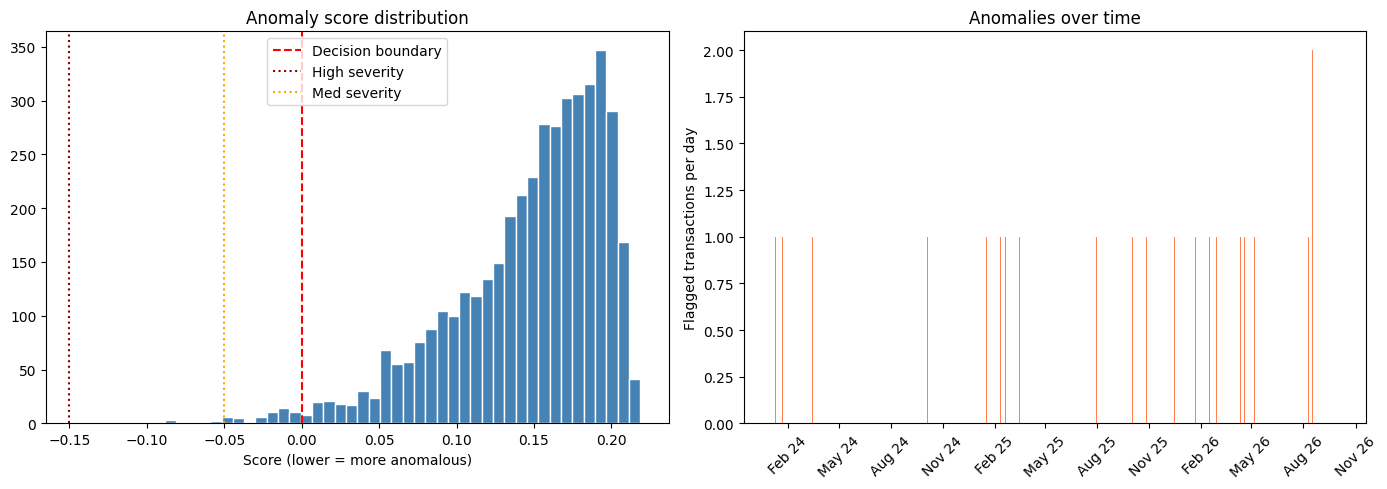

In [ ]:
model, merchant_stats = au.fit_user_anomaly(df)

# Score every row
scored = au.detect_anomalies(df, model, merchant_stats)

print(f"Rows scored: {len(scored)}")
print(f"Flagged as anomaly: {scored['is_anomaly'].sum()} "
      f"({scored['is_anomaly'].mean():.1%})")
print(f"\nSeverity breakdown:")
print(scored['severity'].value_counts())

print(f"\nAnomaly score distribution:")
print(scored['anomaly_score'].describe().round(4))

# Plot score distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.hist(scored['anomaly_score'], bins=50, color='steelblue', edgecolor='white')
ax1.axvline(0, color='red', linestyle='--', lw=1.5, label='Decision boundary')
ax1.axvline(au.SEVERITY_HIGH, color='darkred', linestyle=':', lw=1.5, label='High severity')
ax1.axvline(au.SEVERITY_MED,  color='orange',  linestyle=':', lw=1.5, label='Med severity')
ax1.set_title('Anomaly score distribution')
ax1.set_xlabel('Score (lower = more anomalous)')
ax1.legend()

scored_time = scored.copy()
scored_time['date'] = pd.to_datetime(scored_time['timestamp']).dt.date
daily_flag = scored_time.groupby('date')['is_anomaly'].sum().reset_index()
ax2.bar(pd.to_datetime(daily_flag['date']), daily_flag['is_anomaly'],
        color='coral', width=1)
ax2.set_title('Anomalies over time')
ax2.set_ylabel('Flagged transactions per day')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/anomaly_scores.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 6 — Inspect the top flagged transactions

In [ ]:
flagged = scored[scored['is_anomaly']].sort_values('anomaly_score').copy()

print(f"Top 20 most anomalous transactions:\n")
print(flagged[['timestamp', 'merchant_name', 'category',
               'amount', 'severity', 'anomaly_score']]
      .head(20).to_string(index=False))

print(f"\nFlagged by category:")
print(flagged['category'].value_counts())

print(f"\nFlagged by transaction type:")
print(flagged['transaction_type'].value_counts())

print(f"\nTop flagged merchants (by count):")
print(flagged['merchant_name'].value_counts().head(15))

Top 20 most anomalous transactions:

          timestamp                             merchant_name     category  amount severity  anomaly_score
2025-06-09 18:00:25  Cisco Agencies Ltd All Stock Agrovet Kam    necessity 45000.0   medium      -0.146741
2025-06-09 17:51:54                                Grace Amoi       social 22000.0   medium      -0.123321
2025-10-27 15:12:32                            Moringa School    necessity  3500.0   medium      -0.098905
2024-03-15 14:33:15  Birkan &Amp; Sons Co Ltd Sigalame Mkt Mi    necessity  5000.0   medium      -0.094107
2025-12-06 10:59:16                           Naivas Syokimau    necessity  4219.0   medium      -0.087461
2026-07-31 14:48:17                    Maa Properties Limited    necessity  3350.0   medium      -0.087115
2025-01-17 11:59:02                            Fuzzel Couture aspirational  4900.0   medium      -0.085756
2026-03-06 13:58:31               Speedaf Logistics Kenya Ltd aspirational  2650.0   medium      -0.058868


## Cell 7 — Read explanations for the most anomalous transactions

In [ ]:
top5 = flagged.head(5)
for _, row in top5.iterrows():
    print(f"{'='*60}")
    print(f"Receipt:  {row['receipt_no']}")
    print(f"Date:     {row['timestamp']}")
    print(f"Merchant: {row['merchant_name']}")
    print(f"Amount:   Ksh {row['amount']:,.2f}  ({row['category']})")
    print(f"Severity: {row['severity']}  (score: {row['anomaly_score']:.4f})")
    print(f"Reasons:")
    for r in au.explain_anomaly(row, df, merchant_stats):
        print(f"  • {r}")
    print()

Receipt:  TF967GEOOQ
Date:     2025-06-09 18:00:25
Merchant: Cisco Agencies Ltd All Stock Agrovet Kam
Amount:   Ksh 45,000.00  (necessity)
Severity: medium  (score: -0.1467)
Reasons:
  • This transaction is unusual based on your spending patterns (anomaly score: -0.147).

Receipt:  TF977EJT6R
Date:     2025-06-09 17:51:54
Merchant: Grace Amoi
Amount:   Ksh 22,000.00  (social)
Severity: medium  (score: -0.1233)
Reasons:
  • Amount (Ksh 22,000) is 244.4x your usual spend at Grace Amoi (median Ksh 90).
  • Your social spend in the last 30 days (Ksh 9,751) is 2.1x your usual monthly amount (Ksh 4,728).

Receipt:  TJR5E8J94H
Date:     2025-10-27 15:12:32
Merchant: Moringa School
Amount:   Ksh 3,500.00  (necessity)
Severity: medium  (score: -0.0989)
Reasons:
  • This transaction is unusual based on your spending patterns (anomaly score: -0.099).

Receipt:  SCF84AA8ZG
Date:     2024-03-15 14:33:15
Merchant: Birkan &Amp; Sons Co Ltd Sigalame Mkt Mi
Amount:   Ksh 5,000.00  (necessity)
Severity:

## Cell 8 — Weekly category alerts
Catches week-level overspending that wouldn't show up as a single anomalous transaction.

Weekly category alerts: 64

                 week     category  week_total  baseline_avg  zscore severity                                                                                                   message
2025-06-09/2025-06-15       social    23490.00       2305.17   40.09     high    Social spend this week (Ksh 23,490) is 40.1 standard deviations above your 6-week average (Ksh 2,305).
2024-03-04/2024-03-10    necessity    20050.00       1078.50   21.02     high Necessity spend this week (Ksh 20,050) is 21.0 standard deviations above your 6-week average (Ksh 1,078).
2025-01-13/2025-01-19 aspirational     5158.75        607.74   10.29     high Aspirational spend this week (Ksh 5,159) is 10.3 standard deviations above your 6-week average (Ksh 608).
2025-06-16/2025-06-22 aspirational     1678.04        444.39    9.20     high  Aspirational spend this week (Ksh 1,678) is 9.2 standard deviations above your 6-week average (Ksh 444).
2024-03-04/2024-03-10       social     3879.00      

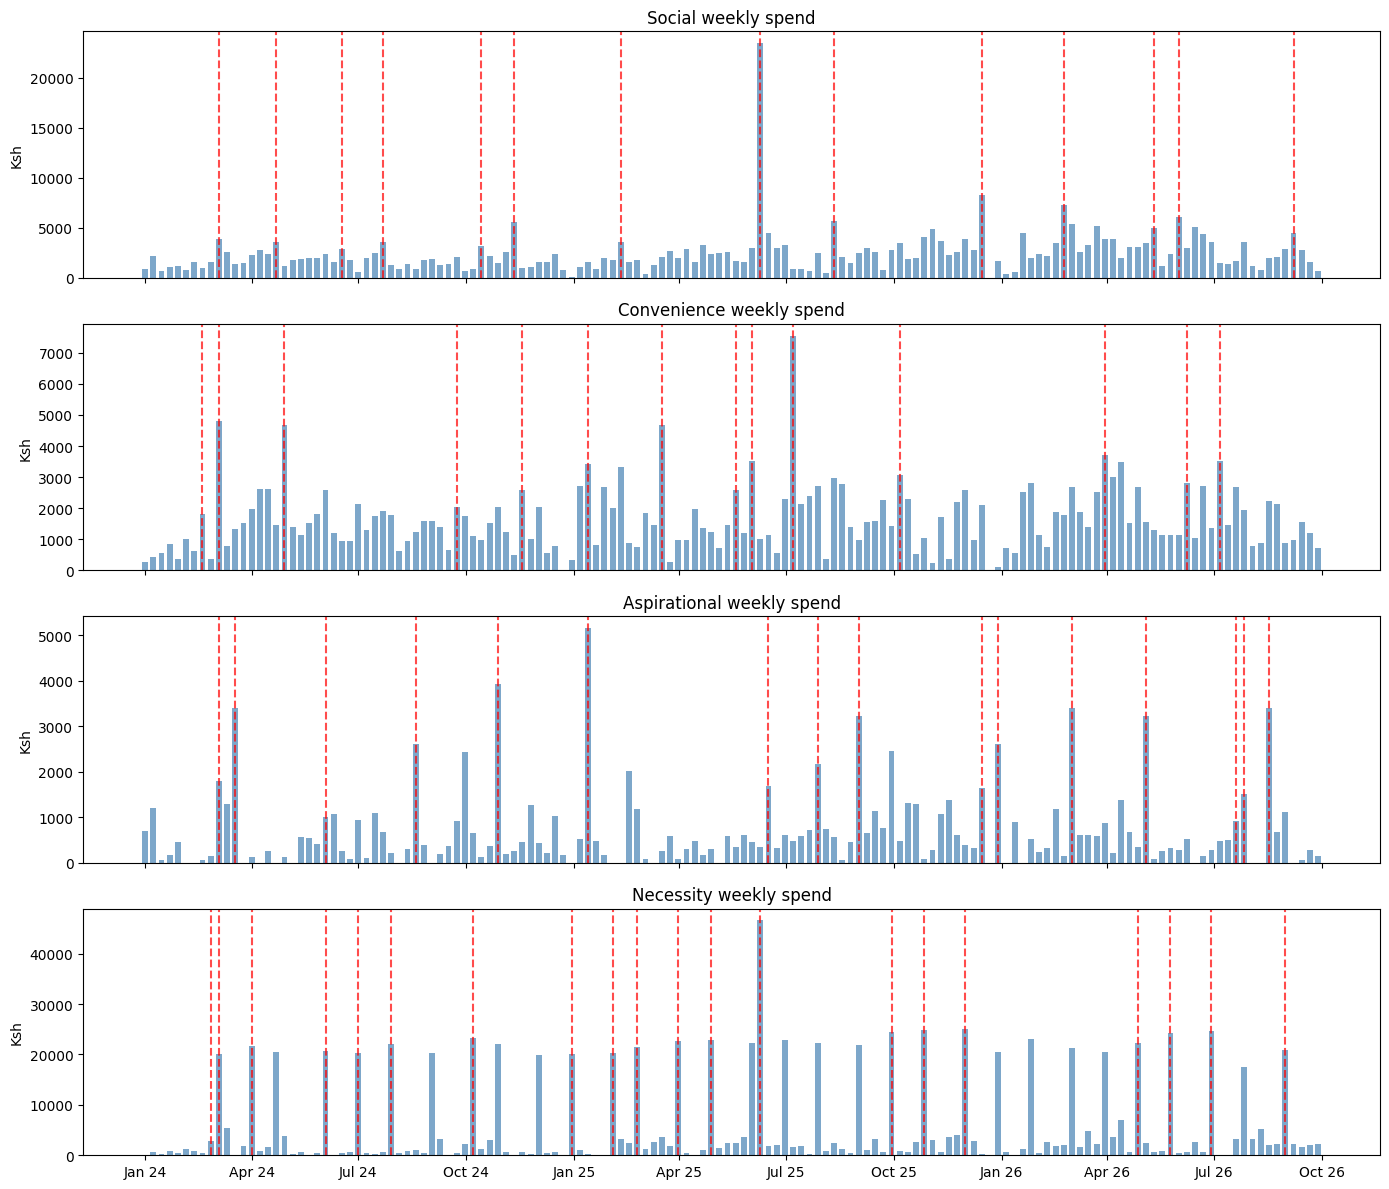

In [ ]:
cat_alerts = au.weekly_category_check(df)

if cat_alerts.empty:
    print("No weekly category alerts.")
else:
    print(f"Weekly category alerts: {len(cat_alerts)}")
    print()
    print(cat_alerts[['week', 'category', 'week_total',
                       'baseline_avg', 'zscore', 'severity', 'message']]
          .sort_values('zscore', ascending=False)
          .head(15).to_string(index=False))

    # Plot weekly spend per category
    debit = df[df['is_debit'] & ~df['transaction_type'].isin(au.SKIP_TYPES) &
               ~df['category'].isin(au.SKIP_CATEGORIES)].copy()
    debit['week'] = pd.to_datetime(debit['timestamp']).dt.to_period('W').dt.start_time

    cats_to_plot = [c for c in ['social','convenience','aspirational','necessity']
                    if c in debit['category'].unique()]
    fig, axes = plt.subplots(len(cats_to_plot), 1,
                             figsize=(14, 3 * len(cats_to_plot)), sharex=True)
    if len(cats_to_plot) == 1:
        axes = [axes]

    for ax, cat in zip(axes, cats_to_plot):
        weekly = (debit[debit['category'] == cat]
                  .groupby('week')['amount'].sum().reset_index())
        ax.bar(weekly['week'], weekly['amount'], width=5,
               color='steelblue', alpha=0.7)
        # Mark alert weeks
        alerts_cat = cat_alerts[cat_alerts['category'] == cat]
        if not alerts_cat.empty:
            alert_weeks = pd.to_datetime(
                alerts_cat['week'].str.split('/').str[0])
            for aw in alert_weeks:
                ax.axvline(aw, color='red', linestyle='--', lw=1.5, alpha=0.7)
        ax.set_title(f'{cat.title()} weekly spend')
        ax.set_ylabel('Ksh')
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))

    plt.tight_layout()
    plt.savefig(f'{MODEL_DIR}/weekly_category_alerts.png',
                dpi=150, bbox_inches='tight')
    plt.show()

## Cell 9 — Evaluation: inject synthetic anomalies
Since there is no ground-truth anomaly label, we inject known anomalies into a held-out period
and measure recall and false-positive rate. This is the standard approach for unsupervised anomaly detection.

In [ ]:
# Hold out the last 90 days
cutoff = df['timestamp'].max() - pd.Timedelta(days=90)
train  = df[df['timestamp'] <= cutoff].copy()
test   = df[df['timestamp'] >  cutoff].copy()

# Train on history only
model_eval, stats_eval = au.fit_user_anomaly(train)

# Inject 10 synthetic anomalies into the test set
rng = np.random.default_rng(42)
injected = test.sample(10, random_state=42).copy()

# Type 1: amount 10x the merchant median
for idx in injected.index[:4]:
    med = stats_eval['median'].get(str(test.loc[idx, 'merchant_id']),
                                   test['amount'].median())
    test.loc[idx, 'amount']     = med * 10
    test.loc[idx, 'amount_out'] = med * 10

# Type 2: unusual hour (3 AM)
for idx in injected.index[4:7]:
    test.loc[idx, 'timestamp'] = (pd.to_datetime(test.loc[idx, 'timestamp'])
                                  .replace(hour=3))

# Type 3: duplicate charge (amount identical to another recent transaction)
for idx in injected.index[7:]:
    similar = test[test['merchant_id'] == test.loc[idx, 'merchant_id']]
    if len(similar) > 1:
        test.loc[idx, 'amount'] = float(similar['amount'].iloc[0])

injected_indices = set(injected.index)

# Score the test set
scored_eval = au.detect_anomalies(test, model_eval, stats_eval)
scored_eval.index = test.index[:len(scored_eval)]

flagged_indices = set(scored_eval[scored_eval['is_anomaly']].index)
true_positives  = flagged_indices & injected_indices
false_positives = flagged_indices - injected_indices
false_negatives = injected_indices - flagged_indices

recall    = len(true_positives) / len(injected_indices)
precision = len(true_positives) / len(flagged_indices) if flagged_indices else 0
fpr       = len(false_positives) / (len(test) - len(injected_indices))

print("Synthetic anomaly injection evaluation")
print(f"  Injected anomalies:  {len(injected_indices)}")
print(f"  Total flagged:       {len(flagged_indices)}")
print(f"  True positives:      {len(true_positives)}")
print(f"  False positives:     {len(false_positives)}")
print(f"  False negatives:     {len(false_negatives)}")
print()
print(f"  Recall:    {recall:.0%}  (% of injected anomalies caught)")
print(f"  Precision: {precision:.0%}  (% of flags that were real)")
print(f"  FPR:       {fpr:.1%}  (% of normal transactions wrongly flagged)")
print()
print(f"  Alerts per month (false positives only): "
      f"{len(false_positives) / 3:.1f}")

Synthetic anomaly injection evaluation
  Injected anomalies:  10
  Total flagged:       10
  True positives:      0
  False positives:     10
  False negatives:     10

  Recall:    0%  (% of injected anomalies caught)
  Precision: 0%  (% of flags that were real)
  FPR:       1.8%  (% of normal transactions wrongly flagged)

  Alerts per month (false positives only): 3.3


## Cell 10 — Save model and verify the full_scan JSON output

In [ ]:
# Save
model_path = f'{MODEL_DIR}/anomaly_ivan.pkl'
joblib.dump({'model': model, 'merchant_stats': merchant_stats}, model_path)

meta = {
    'user_id':        'ivan',
    'trained_at':     datetime.now().isoformat(timespec='seconds'),
    'n_train_rows':   int(len(scored)),
    'contamination':  au.CONTAMINATION,
    'n_flagged':      int(scored['is_anomaly'].sum()),
    'flag_rate':      round(float(scored['is_anomaly'].mean()), 4),
    'severity_counts': scored['severity'].value_counts().to_dict(),
}
Path(f'{MODEL_DIR}/anomaly_meta.json').write_text(json.dumps(meta, indent=2))

print("Saved:")
for f in [model_path, f'{MODEL_DIR}/anomaly_meta.json', UTILS_FILE]:
    print(" ", f)
print()
print(json.dumps(meta, indent=2))

# Reload exactly as FastAPI will
loaded   = joblib.load(model_path)
scan_out = au.full_scan(df, loaded['model'], loaded['merchant_stats'])

print(f"\nfull_scan() output:")
print(f"  ready:               {scan_out['ready']}")
print(f"  n_tx_scanned:        {scan_out['n_tx_scanned']}")
print(f"  n_tx_flagged:        {scan_out['n_tx_flagged']}")
print(f"  n_category_alerts:   {scan_out['n_category_alerts']}")
print(f"\nTop 3 transaction anomalies:")
for a in scan_out['transaction_anomalies'][:3]:
    print(f"  {a['timestamp'][:10]}  {a['merchant_name']:<30}"
          f"  Ksh {a['amount']:>8,.0f}  {a['severity']}")
    for r in a['reasons']:
        print(f"    • {r}")

print(f"\nTop 3 category alerts:")
for a in scan_out['category_alerts'][:3]:
    print(f"  {a['week']}  {a['message']}")

Saved:
  /content/drive/MyDrive/Tajirika/models/anomaly/anomaly_ivan.pkl
  /content/drive/MyDrive/Tajirika/models/anomaly/anomaly_meta.json
  /content/drive/MyDrive/Tajirika/models/anomaly/anomaly_utils.py

{
  "user_id": "ivan",
  "trained_at": "2026-11-15T07:02:16",
  "n_train_rows": 4230,
  "contamination": 0.015,
  "n_flagged": 48,
  "flag_rate": 0.0113,
  "severity_counts": {
    "normal": 4182,
    "low": 38,
    "medium": 10
  }
}

full_scan() output:
  ready:               True
  n_tx_scanned:        4230
  n_tx_flagged:        48
  n_category_alerts:   64

Top 3 transaction anomalies:
  2025-06-09  Cisco Agencies Ltd All Stock Agrovet Kam  Ksh   45,000  medium
    • This transaction is unusual based on your spending patterns (anomaly score: -0.147).
  2025-06-09  Grace Amoi                      Ksh   22,000  medium
    • Amount (Ksh 22,000) is 244.4x your usual spend at Grace Amoi (median Ksh 90).
    • Your social spend in the last 30 days (Ksh 9,751) is 2.1x your usual month